In [207]:
# review analysis

In [208]:
# step1: import libraries
import pandas as pd
import matplotlib.pyplot as plt



In [209]:
# step2: load dataset

df = pd.DataFrame({
    "Review":[
        "I love food",
        "MoMo was awesome",
        "It was yuck",
        "That was okay"
    ],
    "Rating":[5,4,2,3]
})

df

,Review,Rating
0,I love food,5
1,MoMo was awesome,4
2,It was yuck,2
3,That was okay,3


In [210]:
# 4-positive, 3-neutral, <3 negative

In [211]:
def method(value):
    if value<3:
        return "Negative"
    elif value==3:
        return "Neutral"
    else:
        return "Positive"

method(1)

'Negative'

In [212]:
df['sentiment'] = df['Rating'].apply(method)

In [213]:
df

,Review,Rating,sentiment
0,I love food,5,Positive
1,MoMo was awesome,4,Positive
2,It was yuck,2,Negative
3,That was okay,3,Neutral


In [214]:
# step3: Data Understanding and EDA

print(df.shape)

(4, 3)


In [215]:
# Column information
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Review     4 non-null      str  
 1   Rating     4 non-null      int64
 2   sentiment  4 non-null      str  
dtypes: int64(1), str(2)
memory usage: 228.0 bytes
None


In [216]:
# Statistical summary
print(df.describe())

         Rating
count  4.000000
mean   3.500000
std    1.290994
min    2.000000
25%    2.750000
50%    3.500000
75%    4.250000
max    5.000000


In [217]:
# Missing values
print(df.isnull().sum())

Review       0
Rating       0
sentiment    0
dtype: int64


In [218]:
# Duplicate values
print(df.duplicated().sum())

0


In [219]:
# Sentiment distribution
print(df["sentiment"].value_counts())

sentiment
Positive    2
Negative    1
Neutral     1
Name: count, dtype: int64


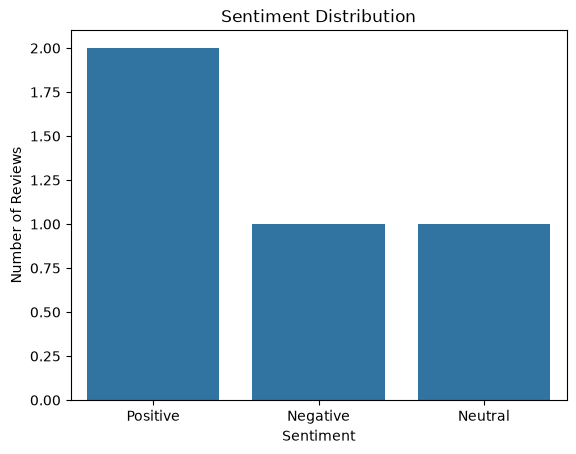

In [220]:
import seaborn as sns

sns.countplot(data=df, x="sentiment")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [221]:
# step4: Data Preprocessing

import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
 
# Create the lemmatizer object once
lemmatizer = WordNetLemmatizer()

# Keep negation words because they affect sentiment
stop_words = stop_words - {"not", "no", "nor"}

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>|http\S+|www\S+|@\w+|[^a-z\s]", "", text)
    words = word_tokenize(text)
    words = [
        word for word in words
        if word not in stopwords.words('english')
    ]
    words = [lemmatizer.lemmatize(lemmatizer.lemmatize(word, pos='v'), pos='n') for word in words]
    words = [word for word in words if len(word)>1]
    return " ".join(words)


# Apply preprocessing
df["cleaned_review"] = df["Review"].apply(clean_text)

df

,Review,Rating,sentiment,cleaned_review
0,I love food,5,Positive,love food
1,MoMo was awesome,4,Positive,momo awesome
2,It was yuck,2,Negative,yuck
3,That was okay,3,Neutral,okay


In [222]:
text = "I REALLY love this Product!!! It's amazing 123. \n"

In [223]:
clean_text(text)

'really love product amaze'

In [224]:
# step5: Feature Extraction
from sklearn.feature_extraction.text import TfidfVectorizer

# TF_IDF -->
vectiozer = TfidfVectorizer()

# conver Text to TF-IDF numerical values 
d = vectiozer.fit_transform(df['cleaned_review'])

In [225]:
d.shape

(4, 6)

In [226]:
d.toarray()[0]

array([0.        , 0.70710678, 0.70710678, 0.        , 0.        ,
       0.        ])

In [227]:
vectiozer.get_feature_names_out()

array(['awesome', 'food', 'love', 'momo', 'okay', 'yuck'], dtype=object)

In [228]:
# step6: train-test-split
from sklearn.model_selection import train_test_split

# Input features
X = pd.DataFrame(d.toarray(), columns=vectiozer.get_feature_names_out())

# Target labels
y = df["sentiment"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 3
Testing data: 1


In [229]:
X

,awesome,food,love,momo,okay,yuck
0,0.000000,0.707107,0.707107,0.000000,0.0,0.0
1,0.707107,0.000000,0.000000,0.707107,0.0,0.0
2,0.000000,0.000000,0.000000,0.000000,0.0,1.0
3,0.000000,0.000000,0.000000,0.000000,1.0,0.0


In [230]:
y

0    Positive
1    Positive
2    Negative
3     Neutral
Name: sentiment, dtype: str

In [231]:
# step7: model training
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression()
logistic_model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [232]:
# step8: model evaluation
from sklearn.metrics import accuracy_score,confusion_matrix,ConfusionMatrixDisplay

y_pred = logistic_model.predict(X_test)
y_pred

array(['Negative'], dtype=object)

In [233]:
accuracy_score(y_test, y_pred)

0.0

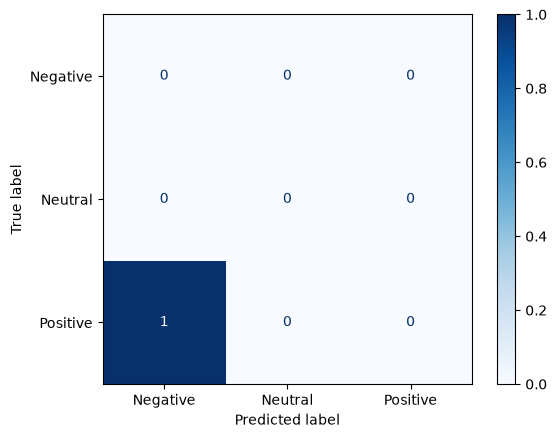

In [234]:
# Calculate confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=logistic_model.classes_
)

# Display
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=logistic_model.classes_
).plot(cmap="Blues")

plt.show()

In [235]:
# predict new review
reviews = "This product is excellent and amazing"

# preprocess 
reviews_preprocessed = clean_text(reviews)
                                      
reviews_preprocessed_array = vectiozer.transform([reviews_preprocessed])

In [236]:
p = reviews_preprocessed_array.toarray()

p

array([[0., 0., 0., 0., 0., 0.]])

In [237]:
logistic_model.predict(p)

/home/hemraj/tf312/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array(['Negative'], dtype=object)